In [3]:
import numpy as np
import matplotlib.pyplot as plt


def symmetric_eigen(matrix, tol=1e-13, max_steps=1000):
    work = np.array(matrix, dtype=float, copy=True)
    n = work.shape[0]
    vectors = np.eye(n)
    threshold = tol * max(1.0, np.linalg.norm(work, ord="fro"))

    for _ in range(max_steps):
        upper = np.abs(np.triu(work, k=1))
        p, q = np.unravel_index(np.argmax(upper), upper.shape)
        if upper[p, q] <= threshold:
            break

        angle = 0.5 * np.arctan2(
            2.0 * work[p, q], work[q, q] - work[p, p]
        )
        c, s = np.cos(angle), np.sin(angle)
        rotation = np.eye(n)
        rotation[p, p] = rotation[q, q] = c
        rotation[p, q] = s
        rotation[q, p] = -s

        work = rotation.T @ work @ rotation
        vectors = vectors @ rotation
    else:
        raise RuntimeError("Did not converge")

    values = np.diag(work)
    order = np.argsort(values)[::-1]
    values, vectors = values[order], vectors[:, order]

    
    columns = np.arange(n)
    pivots = np.argmax(np.abs(vectors), axis=0)
    vectors *= np.sign(vectors[pivots, columns])

    return values, vectors



In [4]:
A = np.array([
    [12, 15, 18, 20, 22],
    [14, 17, 19, 21, 23],
    [16, 18, 21, 24, 26],
    [18, 20, 23, 25, 28],
    [20, 22, 25, 28, 30],
], dtype=float)

values, V = symmetric_eigen(A.T @ A)
sigma = np.sqrt(values)
U = (A @ V) / sigma                    
assert np.allclose(U.T @ U, np.eye(5), atol=1e-8)
assert np.allclose(V.T @ V, np.eye(5), atol=1e-8)
assert np.allclose((U * sigma) @ V.T, A)

print("Q1 singular values:", sigma)
print("U:\n", U)
print("V:\n", V)



Q1 singular values: [107.311048   2.045912   0.843355   0.618166   0.244631]
U:
 [[ 0.369749 -0.792093  0.008978 -0.059166  0.481968]
 [ 0.397062 -0.109507  0.690825  0.388343 -0.449778]
 [ 0.444236 -0.152559 -0.668558  0.024934 -0.576011]
 [ 0.480738  0.288809  0.220524 -0.79802   0.003767]
 [ 0.526472  0.503898 -0.164561  0.456324  0.483324]]
V:
 [[ 0.338142  0.878508 -0.28391  -0.181355  0.019748]
 [ 0.38663   0.182239  0.752686  0.391322 -0.312468]
 [ 0.444944 -0.147615  0.243764 -0.176639  0.830429]
 [ 0.495332 -0.231473 -0.537287  0.642058 -0.012258]
 [ 0.541155 -0.345895 -0.068992 -0.608718 -0.460663]]


In [5]:

errors = []

for k in range(1, 6):
    Ak = np.zeros_like(A)
    for i in range(k):
        Ak += sigma[i] * np.outer(U[:, i], V[:, i])

    error = np.linalg.norm(A - Ak, ord="fro")
    assert np.isclose(error, np.linalg.norm(sigma[k:]), atol=1e-8)
    errors.append(error)
    print(f"k={k}, Frobenius error={error:.6f}")
    if 2 <= k <= 4:
        print(Ak)

    print("\n")






k=1, Frobenius error=2.310622


k=2, Frobenius error=1.073881
[[11.993188 15.045455 17.893783 20.028996 22.032573]
 [14.211118 16.433155 18.991756 21.157548 23.135638]
 [15.845501 18.374326 21.25718  23.685437 25.905571]
 [17.963319 20.053346 22.866762 25.416669 27.71297 ]
 [20.009421 22.03102  24.985471 27.745768 30.216602]]


k=3, Frobenius error=0.664811
[[11.991039 15.051154 17.895628 20.024928 22.032051]
 [14.045709 16.871678 19.133776 20.844518 23.095443]
 [16.005578 17.949938 21.119738 23.988376 25.94447 ]
 [17.910518 20.193331 22.912097 25.316744 27.700138]
 [20.048822 21.926559 24.95164  27.820335 30.226177]]


k=4, Frobenius error=0.244631
[[11.997672 15.036841 17.902089 20.001445 22.054314]
 [14.002173 16.965619 19.091372 20.998651 22.949313]
 [16.002783 17.95597  21.117016 23.998273 25.935088]
 [17.999982 20.000288 22.999235 25.000011 28.000424]
 [19.997665 22.036945 24.901813 28.001449 30.054467]]


k=5, Frobenius error=0.000000




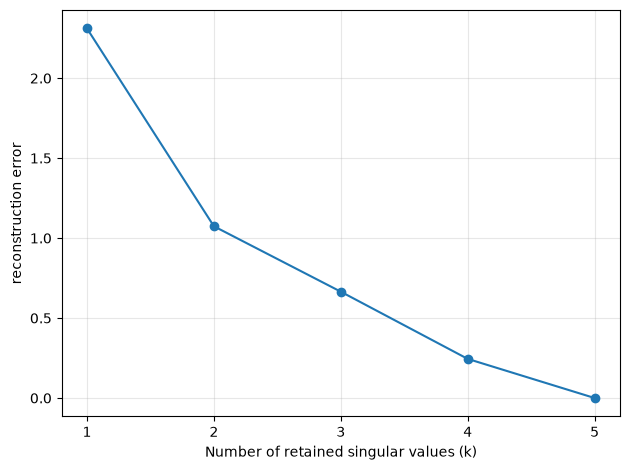

In [6]:
fig, ax = plt.subplots()
ax.plot(range(1, 6), errors, marker="o")
ax.set(
    xlabel="Number of retained singular values (k)",
    ylabel="reconstruction error",
    xticks=range(1, 6),
)
ax.grid(alpha=0.3)
fig.tight_layout()